# 实验6：图像直方图

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

计算与绘制灰度直方图，比较彩色通道分布，理解直方图与像素位置无关。

## 实验原理

灰度直方图统计 0–255 各灰度级的像素个数；OpenCV 范围参数写作 `[0, 256]`（上界不包含）。各柱之和应等于图像像素总数。本实验统计瓶盖照片的灰度与颜色分布。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab06"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 灰度图与直方图

瓶盖浅色背景占比较大，可能在高灰度端出现明显峰值。横轴是灰度，纵轴是像素数。


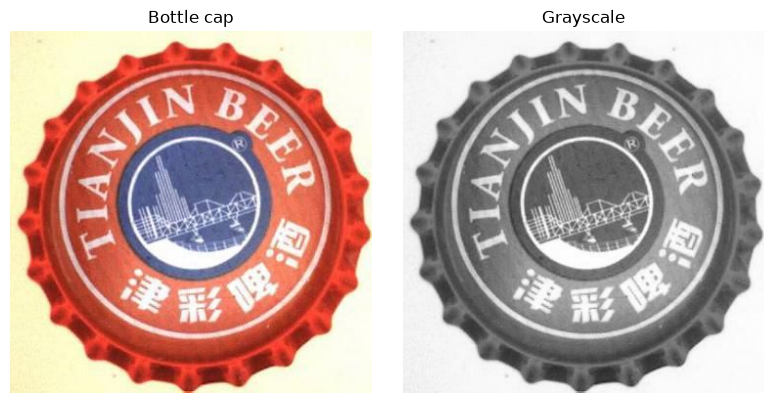

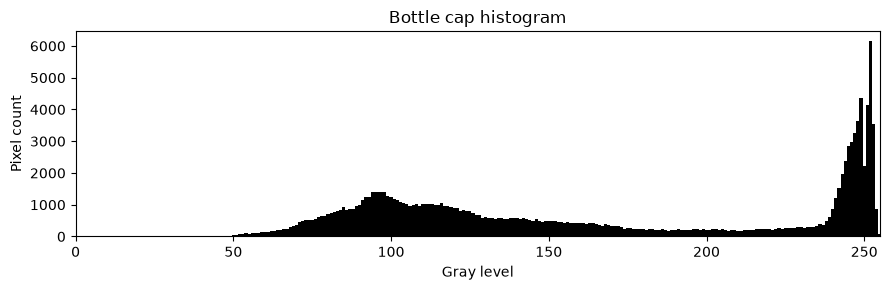

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab06/bottle_cap_gray.png')

In [2]:
image = read_image(ASSETS / "pdf/bottle_cap.png")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
assert int(hist.sum()) == gray.size
show_images({"Bottle cap": image, "Grayscale": gray}, cols=2)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(np.arange(256), hist, width=1, color="black")
ax.set(xlim=(0, 255), xlabel="Gray level", ylabel="Pixel count", title="Bottle cap histogram")
fig.tight_layout(); fig.savefig(OUT / "gray_histogram.png", dpi=120)
plt.show(); plt.close(fig)
np.savetxt(OUT / "gray_histogram.csv", np.column_stack([np.arange(256), hist.astype(int)]),
           fmt="%d", delimiter=",", header="gray_level,pixel_count", comments="")
save_image(OUT / "bottle_cap_gray.png", gray)


## 3. 三个通道的一维直方图

分别画 B、G、R 的分布。三个一维直方图与一个三维联合直方图含义不同。


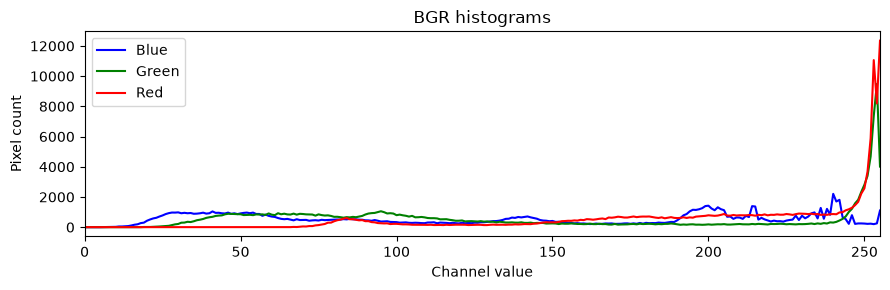

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
for channel, color, label in [(0, "b", "Blue"), (1, "g", "Green"), (2, "r", "Red")]:
    channel_hist = cv2.calcHist([image], [channel], None, [256], [0, 256]).ravel()
    ax.plot(channel_hist, color=color, label=label)
ax.set(xlim=(0, 255), xlabel="Channel value", ylabel="Pixel count", title="BGR histograms")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "color_histograms.png", dpi=120)
plt.show(); plt.close(fig)


## 4. 验证翻转不改变直方图，并计算三维分布

三维联合直方图用每个通道 8 个 bin，共 512 个格子，避免 256³ 带来的额外开销。


In [4]:
flipped = cv2.flip(gray, 1)
hist_flipped = cv2.calcHist([flipped], [0], None, [256], [0, 256]).ravel()
assert np.array_equal(hist, hist_flipped)
joint_hist = cv2.calcHist([image], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
assert int(joint_hist.sum()) == gray.size
np.save(OUT / "bgr_joint_histogram.npy", joint_hist)
print("翻转前后灰度直方图相同；联合直方图形状:", joint_hist.shape)
print("像素总数:", int(joint_hist.sum()))


翻转前后灰度直方图相同；联合直方图形状: (8, 8, 8)
像素总数: 136900


## 记录与思考

1. 浅色背景为什么会影响直方图右侧峰值？
2. 直方图能否唯一确定原图？用翻转实验说明。
3. 将输入换成熊猫照片，比较其灰度分布。
4. 三个独立的一维直方图会丢失哪些跨通道关系？

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab06/`；运行本 Notebook 不会改写原始素材。
